In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils

import thetaflow as thf

E0000 00:00:1793204082.893493   42605 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793204082.898516   42605 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793204082.911586   42605 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793204082.911608   42605 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793204082.911610   42605 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793204082.911612   42605 computation_placer.cc:177] computation placer already registered. Please check linka

## Loading data

In [2]:
df_clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
df_clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")

df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

df_train.head()

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-6359,71.533333,1.0,0.946643,-0.883129,0.0,1.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
1,MB-4357,113.866667,1.0,1.231628,0.879891,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-5530,185.933333,0.0,-0.810247,0.888724,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-5451,189.900000,0.0,-1.362501,-0.895495,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-0481,33.866667,1.0,-0.532195,-0.005152,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Lifetimes and censoring indicators
y_train = df_train["time"] / 12
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 10:]
# For all parameters from the AFT mNoneodel, consider the same set of features as predictors
z_train_mu = df_train.iloc[:, 3:10]
z_train_sigma = df_train.iloc[:, 5:10]
z_train_p = df_train.iloc[:, 3:10]

# Lifetimes and censoring indicators
y_test = df_test["time"] / 12
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_test_mu = df_test.iloc[:, 3:10]
z_test_sigma = df_test.iloc[:, 5:10]
z_test_p = df_test.iloc[:, 3:10]

## Definição da arquitetura da rede neural

In [4]:
def cure_aft_neural_network1(model, seed = None):
    initializer = initializers.GlorotNormal(seed=seed)
    
    # Penalizador para pesos muito grandes
    l2_reg = regularizers.l2(0.01)

    # Camada de Embedding Compartilhada
    # Transforma contagens (0, 1, 2, 3) em embeddings de 2 dimensões
    model.embedding = keras.layers.Embedding(
        input_dim = 4, 
        output_dim = 2, 
        name = "embedding_compartilhado"
    )
    
    # Flatten para conectar à rede densa - 346 entradas
    model.flatten = keras.layers.Flatten(name = "flatten_mutacoes")

    # Camada oculta densa 1
    model.dense1 = keras.layers.Dense(
        units = 64, activation = "gelu", kernel_initializer = initializer, 
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense1"
    )
    model.bn1 = keras.layers.BatchNormalization(name = "bn1")
    model.dropout1 = keras.layers.Dropout(rate = 0.4, seed = seed, name = "drop1")

    # Camada oculta densa 2
    model.dense2 = keras.layers.Dense(
        units = 32, activation = "gelu", kernel_initializer = initializer,
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense2"
    )
    model.bn2 = keras.layers.BatchNormalization(name = "bn2")
    model.dropout2 = keras.layers.Dropout(rate = 0.3, seed=seed, name = "drop2")

    # Camada oculta densa 3
    model.dense3 = keras.layers.Dense(
        units = 16, activation = "gelu", kernel_initializer = initializer, 
        dtype = tf.float32, name = "dense3"
    )
    
    # Camada de saída
    model.dense4 = keras.layers.Dense(
        units = 1, kernel_initializer = initializer, dtype = tf.float32, 
        activation = None, use_bias = True, name = "output"
    )

def cure_aft_neural_network2(model, seed = None):
    initializer = initializers.GlorotNormal(seed=seed)
    
    # Penalizador para pesos muito grandes
    l2_reg = regularizers.l2(0.01)

    # Camada de Embedding Compartilhada
    # Transforma contagens (0, 1, 2, 3) em embeddings de 2 dimensões
    model.embedding = keras.layers.Embedding(
        input_dim = 4, 
        output_dim = 2, 
        name = "embedding_compartilhado"
    )
    
    # Flatten para conectar à rede densa - 346 entradas
    model.flatten = keras.layers.Flatten(name = "flatten_mutacoes")

    # Camada oculta densa 1
    model.dense1 = keras.layers.Dense(
        units = 64, activation = "gelu", kernel_initializer = initializer, 
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense1"
    )
    model.bn1 = keras.layers.BatchNormalization(name = "bn1")
    model.dropout1 = keras.layers.Dropout(rate = 0.4, seed = seed, name = "drop1")

    # Camada oculta densa 2
    model.dense2 = keras.layers.Dense(
        units = 32, activation = "gelu", kernel_initializer = initializer,
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense2"
    )
    model.bn2 = keras.layers.BatchNormalization(name = "bn2")
    model.dropout2 = keras.layers.Dropout(rate = 0.3, seed=seed, name = "drop2")

    # Camada oculta densa 3
    model.dense3 = keras.layers.Dense(
        units = 16, activation = "gelu", kernel_initializer = initializer, 
        dtype = tf.float32, name = "dense3"
    )
    
    # Camada de saída
    model.dense4 = keras.layers.Dense(
        units = 2, kernel_initializer = initializer, dtype = tf.float32, 
        activation = None, use_bias = True, name = "output"
    )

def cure_aft_network_call(model, x_input, training=False):
    # Passagem do embedding e achatamento
    x = model.embedding(x_input)
    x = model.flatten(x)
    
    # Passagem pelo Bloco 1 (com flag training para o BN e Dropout agirem apenas no treino)
    x = model.dense1(x)
    x = model.bn1(x, training=training)
    x = model.dropout1(x, training=training)
    
    # Passagem pelo Bloco 2
    x = model.dense2(x)
    x = model.bn2(x, training=training)
    x = model.dropout2(x, training=training)
    
    # Passagem pelo Bloco 3 e Saída
    x = model.dense3(x)
    return model.dense4(x)

def cure_aft_network_call_nolast(model, x_input, training=False):
    x = model.embedding(x_input)
    x = model.flatten(x)
    
    x = model.dense1(x)
    x = model.bn1(x, training=training)
    x = model.dropout1(x, training=training)
    
    x = model.dense2(x)
    x = model.bn2(x, training=training)
    x = model.dropout2(x, training=training)
    
    x = model.dense3(x)
    return x

## Definição e treinamento do modelo

In [5]:
def train_model( model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, epochs = 15000 ):
    with tf.device("/CPU:0"):
        if(X_train_nn is not None):
            model = thf.ModelNN(model_parameters, model_loss,
                                nn_arch, nn_call, nn_call_nolast,
                                input_dim = (X_train_nn.shape[1], ), seed = 10)
        else:
            model = thf.ModelNN(model_parameters, model_loss,
                                nn_arch, nn_call, nn_call_nolast, seed = 10)
        if(model.neural_network_use):
            model.pre_train_model(epochs = epochs, x = X_train_nn, data = data_train)
        model.train_model(epochs = epochs, x = X_train_nn, data = data_train,
                          shuffle = True,
                          get_covariances = True,
                          validation = True, val_prop = 0.2, force_training_validation = False,
                          optimizer_independent = optimizers.Adam(learning_rate = 0.01),
                          optimizer_nn = optimizers.Adam(learning_rate = 0.01),
                          fine_tune_nn_lr = 0.01, fine_tune_independent_lr = 0.01,
                          early_stopping = True, early_stopping_patience = 50, 
                          early_stopping_warmup = 10, early_stopping_min_delta = 1.0e-3,
                          reduce_lr = True, reduce_lr_warmup = 0,
                          reduce_lr_factor = 0.5, reduce_lr_min_delta = 1.0e-3, reduce_lr_patience = 25,
                          reduce_lr_cooldown = 10, reduce_lr_min_lr = 1.0e-5,
                          fine_tune = True,
                          finetune_early_stopping = True, finetune_early_stopping_patience = 50,
                          finetune_early_stopping_warmup = 10, finetune_early_stopping_min_delta = 1.0e-2,
                          finetune_reduce_lr = True, finetune_reduce_lr_warmup = 0,
                          finetune_reduce_lr_factor = 0.5, finetune_reduce_lr_min_delta = 1.0e-2, finetune_reduce_lr_patience = 25,
                          finetune_reduce_lr_cooldown = 10, finetune_reduce_lr_min_lr = 1.0e-5,
                          deterministic = True,
                          verbose = True, print_freq = 1)
    return model

In [6]:
wb_parameters, wb_loss, wb_survival_cure = cure_aft.build_cure_aft_structure4("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters, ln_loss, ln_survival_cure = cure_aft.build_cure_aft_structure4("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters, ll_loss, ll_survival_cure = cure_aft.build_cure_aft_structure4("ll", z_train_mu, z_train_sigma, z_train_p)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

In [7]:
wb_model = train_model( wb_parameters, wb_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train )

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 78 / 15000 ]  | Avg. Train NLL:  2.01751447 | Avg. Validation NLL:  2.01810551 | Best Avg. Validation NLL:  1.82689035 | Speed:  0.0125827603  epoch/s    | Elapsed Time:  0.981455326  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 79 / 15000 ]  | Avg. Train NLL:  1.95034611 | Avg. Validation NLL:  2.08755302 | Best Avg. Validation NLL:  1.82689035 | Speed:  0.0125694936  epoch/s    | Elapsed Time:  0.99299  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4598 / 15000 ]  | Avg. Train NLL:  1.47395372 | Best Avg. Train NLL:  1.47395372 | Avg. Validation NLL:  1.67443621 | Speed:  0.00457480643  epoch/s    | Elapsed Time:  21.0349598  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 34.902 seconds.


In [8]:
wb_model.save_model("../model_weights/Structure4/wb_model")

Model successfully saved to ../model_weights/Structure4/wb_model.weights.h5 and ../model_weights/Structure4/wb_model_meta.pkl


In [9]:
wb_model = thf.ModelNN(wb_parameters, wb_loss,
                       cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                       input_dim = (X_train_nn.shape[1], ), seed = 10)

wb_model.load_model("../model_weights/Structure4/wb_model")

Model successfully loaded from ../model_weights/Structure4/wb_model.


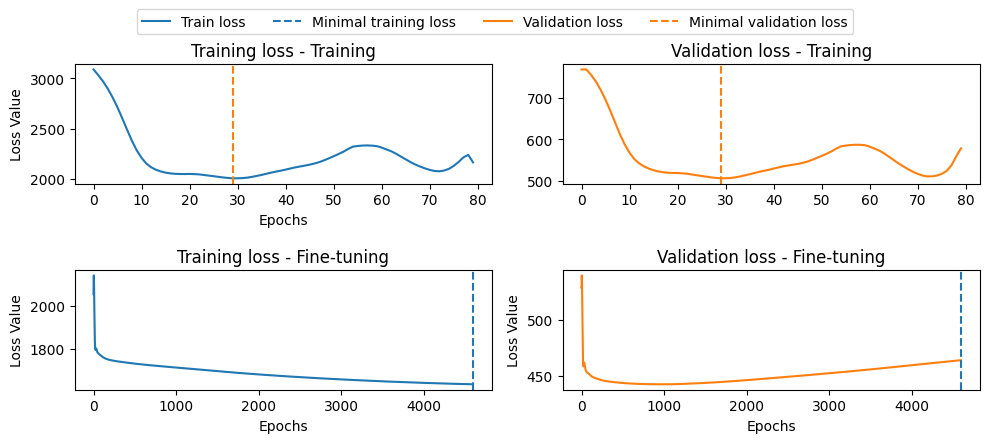

In [10]:
utils.plot_model_convergence( wb_model, figsize = (10,4) )

In [11]:
ln_model = train_model(ln_parameters, ln_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train )

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 71 / 15000 ]  | Avg. Train NLL:  1.9730202 | Avg. Validation NLL:  1.98664713 | Best Avg. Validation NLL:  1.85840309 | Speed:  0.0115372092  epoch/s    | Elapsed Time:  0.819141865  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 72 / 15000 ]  | Avg. Train NLL:  1.94595385 | Avg. Validation NLL:  1.96062112 | Best Avg. Validation NLL:  1.85840309 | Speed:  0.0115397107  epoch/s    | Elapsed Time:  0.830859184  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4971 / 15000 ]  | Avg. Train NLL:  1.45971167 | Best Avg. Train NLL:  1.45971167 | Avg. Validation NLL:  1.84253168 | Speed:  0.00444360496  epoch/s    | Elapsed Time:  22.0891609  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 30.159 seconds.


In [12]:
ln_model.save_model("../model_weights/Structure4/ln_model")

Model successfully saved to ../model_weights/Structure4/ln_model.weights.h5 and ../model_weights/Structure4/ln_model_meta.pkl


In [13]:
ln_model = thf.ModelNN(ln_parameters, ln_loss,
                       cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                       input_dim = (X_train_nn.shape[1], ), seed = 10)

ln_model.load_model("../model_weights/Structure4/ln_model")

Model successfully loaded from ../model_weights/Structure4/ln_model.


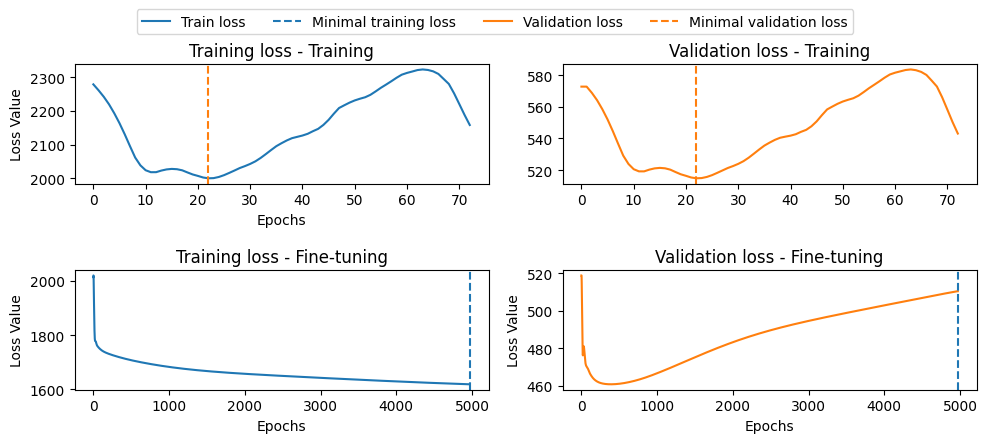

In [14]:
utils.plot_model_convergence( ln_model, figsize = (10,4) )

In [15]:
ll_model = train_model(ll_parameters, ll_loss, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 66 / 15000 ]  | Avg. Train NLL:  2.03270411 | Avg. Validation NLL:  2.21050406 | Best Avg. Validation NLL:  1.77277434 | Speed:  0.0122061176  epoch/s    | Elapsed Time:  0.805603743  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4803 / 15000 ]  | Avg. Train NLL:  1.48257089 | Best Avg. Train NLL:  1.48257089 | Avg. Validation NLL:  1.67130852 | Speed:  0.00471941056  epoch/s    | Elapsed Time:  22.6673279  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 30.736 seconds.


In [16]:
ll_model.save_model("../model_weights/Structure4/ll_model")

Model successfully saved to ../model_weights/Structure4/ll_model.weights.h5 and ../model_weights/Structure4/ll_model_meta.pkl


In [17]:
ll_model = thf.ModelNN(ll_parameters, ll_loss,
                       cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                       input_dim = (X_train_nn.shape[1], ), seed = 10)

ll_model.load_model("../model_weights/Structure4/ll_model")

Model successfully loaded from ../model_weights/Structure4/ll_model.


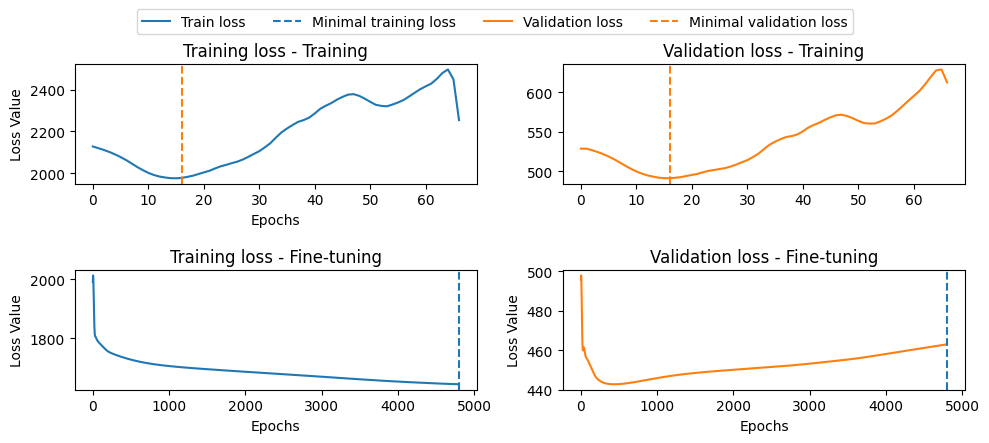

In [18]:
utils.plot_model_convergence( ll_model, figsize = (10,4) )

In [19]:
wb_summary = wb_survival_cure(wb_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
ln_summary = ln_survival_cure(ln_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
ll_summary = ll_survival_cure(ll_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

In [20]:
wb_model.save_model("../model_weights/Structure4/wb_model")
ln_model.save_model("../model_weights/Structure4/ln_model")
ll_model.save_model("../model_weights/Structure4/ll_model")

Model successfully saved to ../model_weights/Structure4/wb_model.weights.h5 and ../model_weights/Structure4/wb_model_meta.pkl
Model successfully saved to ../model_weights/Structure4/ln_model.weights.h5 and ../model_weights/Structure4/ln_model_meta.pkl
Model successfully saved to ../model_weights/Structure4/ll_model.weights.h5 and ../model_weights/Structure4/ll_model_meta.pkl


In [21]:
def parameters_histogram(model_summary, figsize = (12,4)):
    fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = figsize)

    sns.histplot(x = model_summary["mu_train"], ax = ax[0])
    sns.histplot(x = model_summary["sigma_train"], ax = ax[1])
    sns.histplot(x = model_summary["p_train"], ax = ax[2])

    ax[0].set_title("mu - Train")
    ax[1].set_title("sigma - Train")
    ax[2].set_title("p - Train")

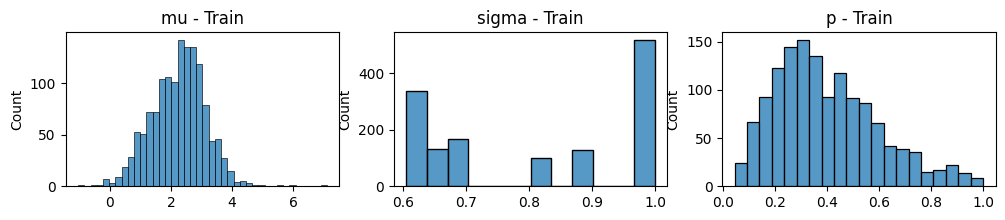

In [22]:
parameters_histogram(wb_summary, figsize = (12,2))

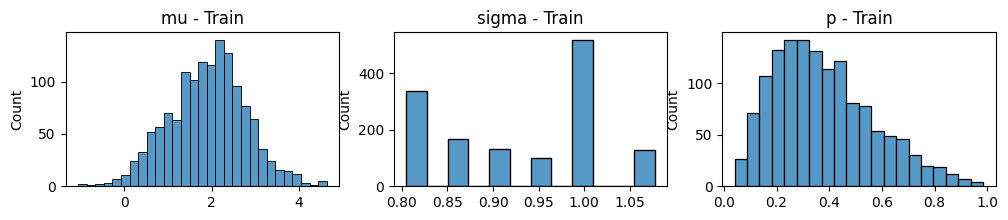

In [23]:
parameters_histogram(ln_summary, figsize = (12,2))

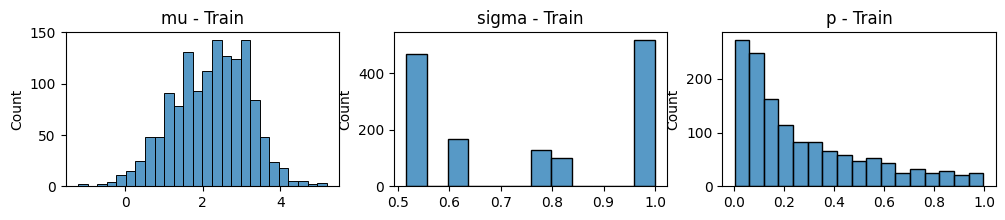

In [24]:
parameters_histogram(ll_summary, figsize = (12,2))

The phenomenon above is interesting and may be caused by an implementation error or it may be intrinsically associated with an identifiability problem in our model assumptions. Given the flexibility of the Log-normal and the Log-logistic distributions with respect to their tails, it may be possible that the model learns that it is more reasonable to assume all patients to be susceptible and make their lifetime distribution tails heavier, simulating a virtual cure fraction.

In order to see that, we can build the predicted average survival curves for both the unrestricted training models and the ones that stop training immediatly before.

In [26]:
import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test

First, we compare the three models global average survival curves

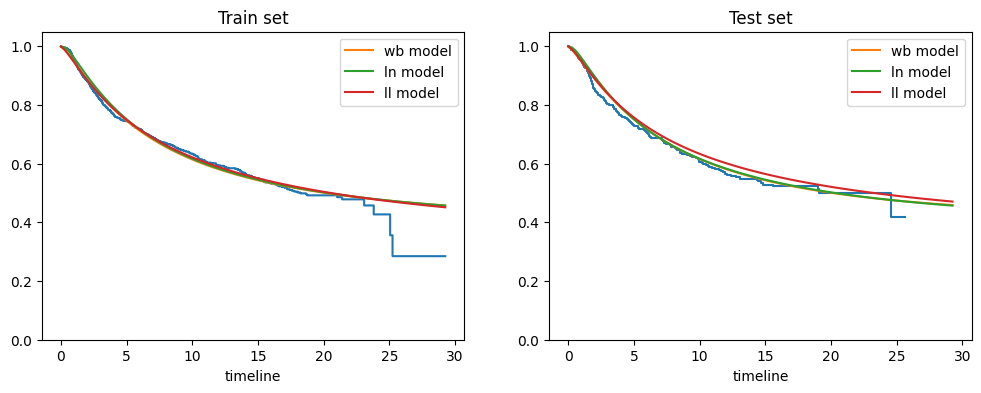

In [27]:
ts_grid = ll_summary["ts_grid"].flatten()

wb_S_ts_train = wb_summary["S_ts_train"]
wb_S_ts_train_avg = np.mean( wb_S_ts_train, axis = 1 )
ln_S_ts_train = ln_summary["S_ts_train"]
ln_S_ts_train_avg = np.mean( ln_S_ts_train, axis = 1 )
ll_S_ts_train = ll_summary["S_ts_train"]
ll_S_ts_train_avg = np.mean( ll_S_ts_train, axis = 1 )

wb_S_ts_test = wb_summary["S_ts_test"]
wb_S_ts_test_avg = np.mean( wb_S_ts_test, axis = 1 )
ln_S_ts_test = ln_summary["S_ts_test"]
ln_S_ts_test_avg = np.mean( ln_S_ts_train, axis = 1 )
ll_S_ts_test = ll_summary["S_ts_test"]
ll_S_ts_test_avg = np.mean( ll_S_ts_test, axis = 1 )

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

km_train = lifelines.KaplanMeierFitter()
km_train.fit(y_train, delta_train)
km_train.plot(ax = ax[0], ci_show = False, show_censors = False, legend = False, label = '_')

ax[0].plot(ts_grid, wb_S_ts_train_avg, label = "wb model")
ax[0].plot(ts_grid, ln_S_ts_train_avg, label = "ln model")
ax[0].plot(ts_grid, ll_S_ts_train_avg, label = "ll model")
ax[0].set_ylim(0, 1.05)
ax[0].legend()
ax[0].set_title("Train set")

km_test = lifelines.KaplanMeierFitter()
km_test.fit(y_test, delta_test)
km_test.plot(ax = ax[1], ci_show = False, show_censors = False, legend = False, label = '_')

ax[1].plot(ts_grid, wb_S_ts_test_avg, label = "wb model")
ax[1].plot(ts_grid, ln_S_ts_test_avg, label = "ln model")
ax[1].plot(ts_grid, ll_S_ts_test_avg, label = "ll model")
ax[1].set_ylim(0, 1.05)
ax[1].legend()
ax[1].set_title("Test set")

plt.show()

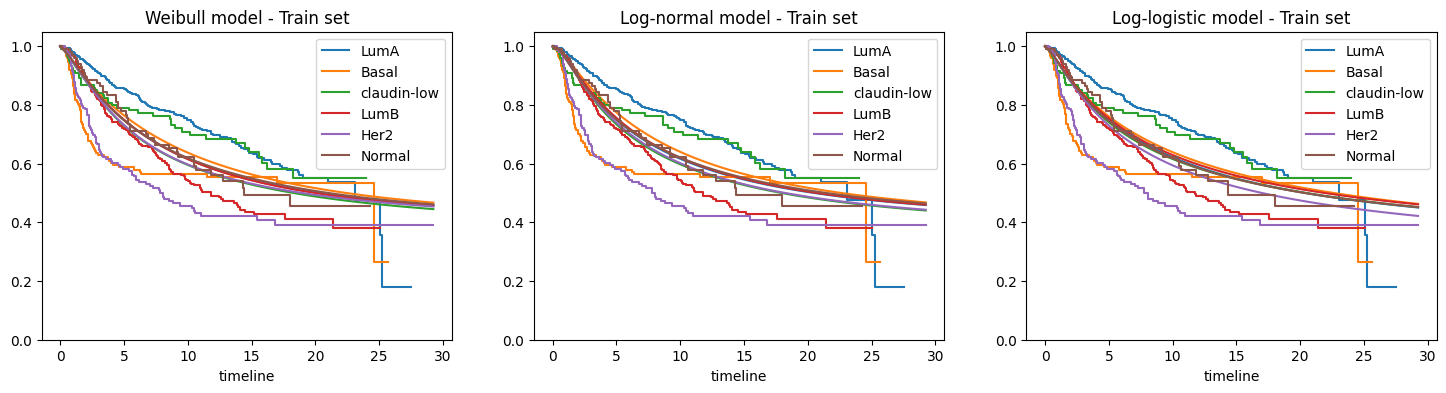

In [28]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18,4))

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
ts_grid = wb_summary["ts_grid"].flatten()
wb_S_ts_train = wb_summary["S_ts_train"].numpy()
ln_S_ts_train = ln_summary["S_ts_train"].numpy()
ll_S_ts_train = ll_summary["S_ts_train"].numpy()

unique_pam50_subtypes = df_clean_train["pam50_subtype"].unique()

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean_train["pam50_subtype"] == subtype
    time = df_clean_train.loc[subtype_patients, "time"] / 12
    delta = df_clean_train.loc[subtype_patients, "delta"]

    wb_S_ts_train_subtype_avg = np.mean(wb_S_ts_train[:, subtype_patients], axis = 1)
    ln_S_ts_train_subtype_avg = np.mean(ln_S_ts_train[:, subtype_patients], axis = 1)
    ll_S_ts_train_subtype_avg = np.mean(ll_S_ts_train[:, subtype_patients], axis = 1)

    ax[0].plot(ts_grid, wb_S_ts_train_subtype_avg, color = colors[i])
    ax[1].plot(ts_grid, ln_S_ts_train_subtype_avg, color = colors[i])
    ax[2].plot(ts_grid, ll_S_ts_train_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(time, delta)
    km.plot(ax = ax[0], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[2], ci_show = False, show_censors = False, label = subtype)

ax[0].set_title("Weibull model - Train set")
ax[0].set_ylim(0, 1.05)
ax[1].set_title("Log-normal model - Train set")
ax[1].set_ylim(0, 1.05)
ax[2].set_title("Log-logistic model - Train set")
ax[2].set_ylim(0, 1.05)

plt.show()

In [31]:
wb_model_summary = wb_model.summary()

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


In [32]:
wb_model_summary

,index,mu_beta[0],mu_beta[0]_se,mu_beta[0]_lower,mu_beta[0]_upper,mu_beta[1],mu_beta[1]_se,mu_beta[1]_lower,mu_beta[1]_upper,mu_beta[2],...,p_beta[4]_lower,p_beta[4]_upper,p_beta[5],p_beta[5]_se,p_beta[5]_lower,p_beta[5]_upper,p_beta[6],p_beta[6]_se,p_beta[6]_lower,p_beta[6]_upper
0,1,0.045777,0.053378,-0.058843,0.150396,-0.081477,0.049401,-0.178301,0.015346,-0.968505,...,-0.835216,0.465545,0.291088,0.655733,-0.994127,1.576302,0.780392,0.500797,-0.201153,1.761937


In [44]:
from scipy.stats import norm

def summary_betas(model, colnames):
    beta_summary = model.summary()
    
    beta_hats = []
    beta_ses = []
    beta_statistics = []
    beta_pvalues = []
    beta_CIs = []
    for j, beta in enumerate(beta_summary.columns[1::4]):
        beta_hat = float( beta_summary.iloc[0,j*4+1] )
        se = float( beta_summary.iloc[0,j*4+2] )
    
        test_statistic = beta_hat / se
        p_value = 2.0 * (1.0 - norm.cdf(np.abs(test_statistic)))
        
        lower = float( beta_summary.iloc[0,j*4+3] )
        upper = float( beta_summary.iloc[0,j*4+4] )
    
        beta_hats.append( beta_hat )
        beta_ses.append( se )
        beta_statistics.append( test_statistic )
        beta_pvalues.append( p_value )
        beta_CIs.append("({} ; {})".format(np.round(lower,4), np.round(upper,4)))
    beta_summary = pd.DataFrame({"Coef": beta_hats, "Se": beta_ses, "Z": beta_statistics, "pvalue": beta_pvalues, "CI(95%)": beta_CIs})
    beta_summary.index = colnames
    beta_summary
    return beta_summary

In [71]:
pd.options.display.float_format = '{:.6f}'.format
mu_colnames = list( np.char.add("mu_", list(z_train_mu.columns)) )
sigma_colnames = list( np.char.add("sigma_", list(z_train_sigma.columns)) )
p_colnames = list( np.char.add("p_", list(z_train_p.columns)) )

colnames = mu_colnames + sigma_colnames + p_colnames
display( summary_betas( wb_model, colnames ) )
pd.options.display.float_format = None

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


,Coef,Se,Z,pvalue,CI(95%)
mu_age_at_diagnosis,0.045777,0.053378,0.857588,0.391120,(-0.0588 ; 0.1504)
mu_npi,-0.081477,0.049401,-1.649315,0.099083,(-0.1783 ; 0.0153)
mu_pam50_subtype_Basal,-0.968505,0.199034,-4.866034,0.000001,(-1.3586 ; -0.5784)
mu_pam50_subtype_Her2,-0.627562,0.184941,-3.393305,0.000691,(-0.99 ; -0.2651)
mu_pam50_subtype_LumB,-0.414535,0.164293,-2.523136,0.011631,(-0.7365 ; -0.0925)
mu_pam50_subtype_Normal,-0.069717,0.342065,-0.203811,0.838501,(-0.7402 ; 0.6007)
mu_pam50_subtype_claudin-low,-0.120343,0.311505,-0.386326,0.699256,(-0.7309 ; 0.4902)
sigma_pam50_subtype_Basal,-0.431622,0.124956,-3.454196,0.000552,(-0.6765 ; -0.1867)
sigma_pam50_subtype_Her2,-0.377926,0.111418,-3.391962,0.000694,(-0.5963 ; -0.1596)
sigma_pam50_subtype_LumB,-0.501456,0.081986,-6.116379,0.000000,(-0.6621 ; -0.3408)


In [75]:
pd.options.display.float_format = '{:.6f}'.format
display( summary_betas( ln_model, colnames ) )
pd.options.display.float_format = None

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


,Coef,Se,Z,pvalue,CI(95%)
mu_age_at_diagnosis,0.109211,0.047333,2.307290,0.021039,(0.0164 ; 0.202)
mu_npi,-0.134142,0.046231,-2.901585,0.003713,(-0.2248 ; -0.0435)
mu_pam50_subtype_Basal,-0.432035,0.248294,-1.740015,0.081856,(-0.9187 ; 0.0546)
mu_pam50_subtype_Her2,-0.219988,0.176174,-1.248698,0.211776,(-0.5653 ; 0.1253)
mu_pam50_subtype_LumB,-0.133320,0.150581,-0.885371,0.375957,(-0.4285 ; 0.1618)
mu_pam50_subtype_Normal,0.090233,0.318230,0.283545,0.776759,(-0.5335 ; 0.714)
mu_pam50_subtype_claudin-low,0.064340,0.331866,0.193875,0.846274,(-0.5861 ; 0.7148)
sigma_pam50_subtype_Basal,-0.100281,0.139750,-0.717575,0.473020,(-0.3742 ; 0.1736)
sigma_pam50_subtype_Her2,-0.155173,0.131120,-1.183445,0.236633,(-0.4122 ; 0.1018)
sigma_pam50_subtype_LumB,-0.216936,0.081496,-2.661918,0.007770,(-0.3767 ; -0.0572)


In [76]:
pd.options.display.float_format = '{:.6f}'.format
display( summary_betas( ll_model, colnames ) )
pd.options.display.float_format = None

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


,Coef,Se,Z,pvalue,CI(95%)
mu_age_at_diagnosis,0.055039,0.051705,1.064486,0.287108,(-0.0463 ; 0.1564)
mu_npi,-0.182342,0.057793,-3.155071,0.001605,(-0.2956 ; -0.0691)
mu_pam50_subtype_Basal,-1.301570,0.240039,-5.422328,0.000000,(-1.772 ; -0.8311)
mu_pam50_subtype_Her2,-0.949818,0.210565,-4.510814,0.000006,(-1.3625 ; -0.5371)
mu_pam50_subtype_LumB,-0.694315,0.167363,-4.148562,0.000033,(-1.0223 ; -0.3663)
mu_pam50_subtype_Normal,0.011234,0.372451,0.030163,0.975937,(-0.7188 ; 0.7412)
mu_pam50_subtype_claudin-low,-0.665189,0.323907,-2.053641,0.040010,(-1.3 ; -0.0303)
sigma_pam50_subtype_Basal,-0.648239,0.145179,-4.465108,0.000008,(-0.9328 ; -0.3637)
sigma_pam50_subtype_Her2,-0.486716,0.121284,-4.013023,0.000060,(-0.7244 ; -0.249)
sigma_pam50_subtype_LumB,-0.660005,0.087771,-7.519642,0.000000,(-0.832 ; -0.488)


As we can see, although the global average curve correctly matches the Kaplan-Meier estimate, when splitting the PAM50 breast cancer subtypes into subgroups, the average survival curves are closely related and do not follow the different patterns seen in different cancer subtypes. Also, we can see that the PAM50 subtype is statistically significant for $\mu$, $\sigma$ and $p$. However, it was not sufficient to properly see the difference in the Kaplan-Meier estimates.

### Peparing different model structures

In [32]:
wb_parameters1, wb_loss1, wb_survival_cure1 = cure_aft.build_cure_aft_structure1("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters1, ln_loss1, ln_survival_cure1 = cure_aft.build_cure_aft_structure1("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters1, ll_loss1, ll_survival_cure1 = cure_aft.build_cure_aft_structure1("ll", z_train_mu, z_train_sigma, z_train_p)

wb_parameters2, wb_loss2, wb_survival_cure2 = cure_aft.build_cure_aft_structure2("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters2, ln_loss2, ln_survival_cure2 = cure_aft.build_cure_aft_structure2("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters2, ll_loss2, ll_survival_cure2 = cure_aft.build_cure_aft_structure2("ll", z_train_mu, z_train_sigma, z_train_p)

wb_parameters3, wb_loss3, wb_survival_cure3 = cure_aft.build_cure_aft_structure3("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters3, ln_loss3, ln_survival_cure3 = cure_aft.build_cure_aft_structure3("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters3, ll_loss3, ll_survival_cure3 = cure_aft.build_cure_aft_structure3("ll", z_train_mu, z_train_sigma, z_train_p)

wb_parameters4, wb_loss4, wb_survival_cure4 = cure_aft.build_cure_aft_structure4("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters4, ln_loss4, ln_survival_cure4 = cure_aft.build_cure_aft_structure4("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters4, ll_loss4, ll_survival_cure4 = cure_aft.build_cure_aft_structure4("ll", z_train_mu, z_train_sigma, z_train_p)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

In [7]:
def train_save_model(model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, structure, filename, epochs = 15000):
    model = train_model( model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, epochs = epochs )
    model.save_model("../model_weights/Structure{}/{}".format(structure, filename))
    print("Successfully saved file Structure{}/{}\n".format(structure, filename))

### Structure 1

In [9]:
train_save_model(wb_parameters1, wb_loss1, None, None, None,
                 None, data_train,
                 1, "wb_model", epochs = 15000)
train_save_model(ln_parameters1, ln_loss1, None, None, None,
                 None, data_train,
                 1, "ln_model", epochs = 15000)
train_save_model(ll_parameters1, ll_loss1, None, None, None,
                 None, data_train,
                 1, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 381 / 15000 ]  | Avg. Train NLL:  8.24940205 | Avg. Validation NLL:  8.05171394 | Best Avg. Validation NLL:  7.9960885 | Speed:  0.00347620412  epoch/s    | Elapsed Time:  1.3244338  s      
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 382 / 15000 ]  | Avg. Train NLL:  8.24763107 | Avg. Validation NLL:  8.05328941 | Best Avg. Validation NLL:  7.9960885 | Speed:  0.00348301837  epoch/s    | Elapsed Time:  1.330513  s   Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 10.901 seconds.
Model successfully saved to ../model_weights/Structure1/wb_model.weights.h5 and ../model_weights/Structure1/wb_model_meta.pkl
Successfully saved file Structure1/wb_model

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 585 / 15000 ]  | Avg. Train NLL:  3.81481767 | Avg. Validation NLL:  3.69365835 | Best Avg. Validation NLL:  3.69361258 | Speed:  0.0

### Structure 2

In [10]:
train_save_model(wb_parameters2, wb_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 2, "wb_model", epochs = 15000)
train_save_model(ln_parameters2, ln_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 2, "ln_model", epochs = 15000)
train_save_model(ll_parameters2, ll_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 2, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 187 / 15000 ]  | Avg. Train NLL:  2.66719365 | Avg. Validation NLL:  2.73421979 | Best Avg. Validation NLL:  2.69933867 | Speed:  0.0217528474  epoch/s    | Elapsed Time:  4.0677824  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 188 / 15000 ]  | Avg. Train NLL:  2.6678946 | Avg. Validation NLL:  2.73489165 | Best Avg. Validation NLL:  2.69933867 | Speed:  0.0217528418  epoch/s    | Elapsed Time:  4.08953428  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3027 / 15000 ]  | Avg. Train NLL:  2.56627274 | Best Avg. Train NLL:  2.56627274 | Avg. Validation NLL:  2.70968199 | Speed:  0.00852774084  epoch/s    | Elapsed Time:  25.8134708  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 39.437 seconds.
Model successfull

### Structure 3

In [11]:
train_save_model(wb_parameters3, wb_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 3, "wb_model", epochs = 15000)
train_save_model(ln_parameters3, ln_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 3, "ln_model", epochs = 15000)
train_save_model(ll_parameters3, ll_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 3, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 438 / 15000 ]  | Avg. Train NLL:  8.82205677 | Avg. Validation NLL:  10.5777111 | Best Avg. Validation NLL:  10.5756006 | Speed:  0.0270093586  epoch/s    | Elapsed Time:  11.8300991  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 439 / 15000 ]  | Avg. Train NLL:  8.81551075 | Avg. Validation NLL:  10.5772152 | Best Avg. Validation NLL:  10.5756006 | Speed:  0.0270126797  epoch/s    | Elapsed Time:  11.8585663  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 9734 / 15000 ]  | Avg. Train NLL:  -25.0604191 | Best Avg. Train NLL:  -25.0604191 | Avg. Validation NLL:  -19.0425854 | Speed:  0.0104299542  epoch/s    | Elapsed Time:  101.525169  s       
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.


/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[2]', 'p_beta[3]', 'p_beta[5]', 'p_beta[6]']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 123.602 seconds.
Model successfully saved to ../model_weights/Structure3/wb_model.weights.h5 and ../model_weights/Structure3/wb_model_meta.pkl
Successfully saved file Structure3/wb_model

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 138 / 15000 ]  | Avg. Train NLL:  4.65229321 | Avg. Validation NLL:  4.73161888 | Best Avg. Validation NLL:  4.60171127 | Speed:  0.023195656  epoch/s    | Elapsed Time:  3.20100045  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 139 / 15000 ]  | Avg. Train NLL:  4.6528163 | Avg. Validation NLL:  4.7322979 | Best Avg. Validation NLL:  4.60171127 | Speed:  0.0231869463  epoch/s    | Elapsed Time:  3.22298551  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 2313 / 15000 ]  | Avg. Train NLL:  3.67299366 | Best Avg. Train NLL:  3.67299366 | Avg. Validation NLL:  4.09221458 | Speed:  0.010179555  

### Structure 4

In [13]:
train_save_model(wb_parameters4, wb_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 4, "wb_model", epochs = 15000)
train_save_model(ln_parameters4, ln_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 4, "ln_model", epochs = 15000)
train_save_model(ll_parameters4, ll_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                 X_train_nn, data_train,
                 4, "ll_model", epochs = 15000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 156 / 15000 ]  | Avg. Train NLL:  2.75742388 | Avg. Validation NLL:  2.93618822 | Best Avg. Validation NLL:  2.79992723 | Speed:  0.0270766653  epoch/s    | Elapsed Time:  4.22396  s      
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 157 / 15000 ]  | Avg. Train NLL:  2.75948334 | Avg. Validation NLL:  2.93901396 | Best Avg. Validation NLL:  2.79992723 | Speed:  0.0270714629  epoch/s    | Elapsed Time:  4.25022  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4995 / 15000 ]  | Avg. Train NLL:  2.45674777 | Best Avg. Train NLL:  2.45674777 | Avg. Validation NLL:  3.10067844 | Speed:  0.00886349287  epoch/s    | Elapsed Time:  44.2731476  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 58.802 seconds.
Model successfully 

/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[0]', 'p_beta[1]', 'p_beta[2]', 'p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]', 'p_nn']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 67.307 seconds.
Model successfully saved to ../model_weights/Structure4/ln_model.weights.h5 and ../model_weights/Structure4/ln_model_meta.pkl
Successfully saved file Structure4/ln_model

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 104 / 15000 ]  | Avg. Train NLL:  2.67086554 | Avg. Validation NLL:  2.7157774 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0208156519  epoch/s    | Elapsed Time:  2.16482782  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 105 / 15000 ]  | Avg. Train NLL:  2.62593579 | Avg. Validation NLL:  2.70491529 | Best Avg. Validation NLL:  2.69935298 | Speed:  0.0208007284  epoch/s    | Elapsed Time:  2.18407655  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 6192 / 15000 ]  | Avg. Train NLL:  -36.9139442 | Best Avg. Train NLL:  -36.9139442 | Avg. Validation NLL:  -35.5817375 | Speed:  0.0082756

/home/natan/.pyenv/versions/3.11.10/lib/python3.11/site-packages/thetaflow/modelnn.py:2609: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]']
Please, double check your loss function definition.
  warnings.warn(


### Loading all models

In [41]:
def load_model(structure, filename, survival_cure_function,
               model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast,
               y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
               y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p):
    
    if(structure == 1):
        model = thf.ModelNN(model_parameters, model_loss, seed = 10)
    else:
        model = thf.ModelNN(model_parameters, model_loss,
                            nn_arch, nn_call, nn_call_nolast,
                            input_dim = (X_train_nn.shape[1], ), seed = 10)

    if(structure == 1):
        model(None)
    model.load_model( "../model_weights/Structure{}/{}".format(structure, filename) )
    
    if(structure == 1):
        model_summary = survival_cure_function(model,
                                               y_train, delta_train, z_train_mu, z_train_sigma, z_train_p,
                                               y_test, delta_test, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
    else:
        model_summary = survival_cure_function(model,
                                               y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                               y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
    return model, model_summary

In [42]:
wb_model1, wb_summary1 = load_model(1, "wb_model", wb_survival_cure1,
                                    wb_parameters1, wb_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)
ln_model1, ln_summary1 = load_model(1, "ln_model", ln_survival_cure1,
                                    ln_parameters1, ln_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)
ll_model1, ll_summary1 = load_model(1, "ll_model", ll_survival_cure1,
                                    ll_parameters1, ll_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure1/wb_model.
Model successfully loaded from ../model_weights/Structure1/ln_model.
Model successfully loaded from ../model_weights/Structure1/ll_model.


In [43]:
wb_model2, wb_summary2 = load_model(2, "wb_model", wb_survival_cure2,
                                    wb_parameters2, wb_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ln_model2, ln_summary2 = load_model(2, "ln_model", ln_survival_cure2,
                                    ln_parameters2, ln_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ll_model2, ll_summary2 = load_model(2, "ll_model", ll_survival_cure2,
                                    ll_parameters2, ll_loss2, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure2/wb_model.
Model successfully loaded from ../model_weights/Structure2/ln_model.
Model successfully loaded from ../model_weights/Structure2/ll_model.


In [44]:
wb_model3, wb_summary3 = load_model(3, "wb_model", wb_survival_cure3,
                                    wb_parameters3, wb_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ln_model3, ln_summary3 = load_model(3, "ln_model", ln_survival_cure3,
                                    ln_parameters3, ln_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ll_model3, ll_summary3 = load_model(3, "ll_model", ll_survival_cure3,
                                    ll_parameters3, ll_loss3, cure_aft_neural_network1, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure3/wb_model.
Model successfully loaded from ../model_weights/Structure3/ln_model.
Model successfully loaded from ../model_weights/Structure3/ll_model.


In [45]:
wb_model4, wb_summary4 = load_model(4, "wb_model", wb_survival_cure4,
                                    wb_parameters4, wb_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ln_model4, ln_summary4 = load_model(4, "ln_model", ln_survival_cure4,
                                    ln_parameters4, ln_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)
ll_model4, ll_summary4 = load_model(4, "ll_model", ll_survival_cure4,
                                    ll_parameters4, ll_loss4, cure_aft_neural_network2, cure_aft_network_call, cure_aft_network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Structure4/wb_model.
Model successfully loaded from ../model_weights/Structure4/ln_model.
Model successfully loaded from ../model_weights/Structure4/ll_model.


### Checking results

In [47]:
def plot_km_subtypes(df, ax = None):
    
    if(ax is None):
        fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

    unique_pam50_subtypes = df["pam50_subtype"].unique()
    
    km = lifelines.KaplanMeierFitter()
    km.fit(df["time"] / 12, df["delta"])
    km.plot(ax = ax[0], ci_show = False, show_censors = False)
    
    for i, subtype in enumerate(unique_pam50_subtypes):
        time = df.loc[df["pam50_subtype"] == subtype, "time"]
        delta = df.loc[df["pam50_subtype"] == subtype, "delta"]
        print(subtype, "-", len(time))
        km = lifelines.KaplanMeierFitter()
        # Years
        km.fit(time / 12, delta)
        km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    
    ax[0].set_ylim(0,1.05)
    ax[1].set_ylim(0,1.05)

In [49]:
df_train

,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-6359,71.533333,1.0,0.946643,-0.883129,0.0,1.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
1,MB-4357,113.866667,1.0,1.231628,0.879891,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-5530,185.933333,0.0,-0.810247,0.888724,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-5451,189.900000,0.0,-1.362501,-0.895495,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-0481,33.866667,1.0,-0.532195,-0.005152,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1381,MB-6163,48.933333,1.0,0.808002,0.906389,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1382,MB-4849,11.000000,1.0,1.570529,0.014280,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1383,MB-7165,147.166667,0.0,-2.491656,1.166072,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1384,MB-4328,199.266667,0.0,0.230331,0.014280,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


KeyError: 'pam50_subtype'

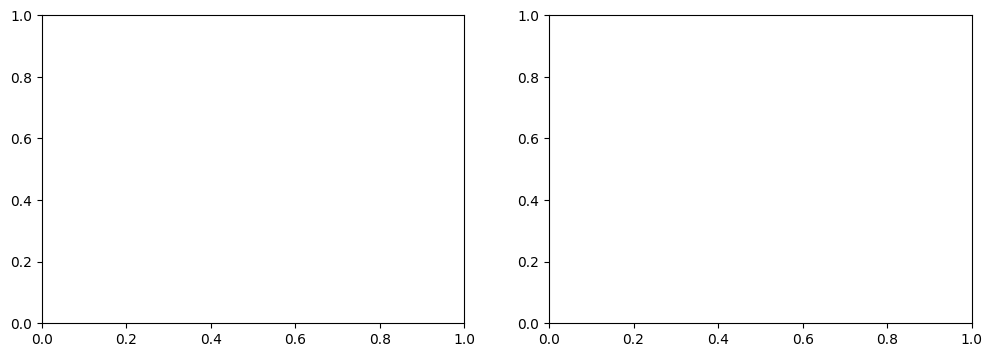

In [48]:
plot_km_subtypes(df_train)